# Questions 5 & 6: Uncertainty and Error Analysis

Analysis of shared 3 ? 5 cross-validation scores and out-of-fold training predictions. The official `test` split is untouched.

The local CSVs in `part2/results/shared_inputs` and the JAX, NumPyro and ArviZ dependencies must be available to rerun the analysis; they are not included in this commit.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd().resolve()
ROOT = cwd if (cwd / 'part2' / 'classification.py').is_file() else cwd.parent
if not (ROOT / 'part2' / 'classification.py').is_file():
    raise FileNotFoundError('Start this notebook from the repository root or part2.')
sys.path.insert(0, str(ROOT))

from part2.classification import load_folds
from part2.embeddings import create_tokenizer, load_embeddings
from part2.error_analysis import extract_tweet_features

SEEDS = [0, 3, 5]
FOLDS = range(5)

## Question 5: Decisions Under Uncertainty & Variance

We verify shared 3 ? 5 CV scores and out-of-fold predictions for three models against the 3,232 deduplicated training tweets. Score-table `pool-baseline` is `pool-baseline-twitter`; Part 1 scores have no matching prediction file.

In [2]:
from part2.error_analysis import (validate_shared_results, paired_oof_predictions,
                                  summarize_oof_features)
import part1.analysis

SHARED_DIR = ROOT / 'part2' / 'results' / 'shared_inputs'
shared_scores = pd.read_csv(SHARED_DIR / 'comparison.csv')
shared_predictions = pd.read_csv(SHARED_DIR / 'predictions.csv')
shared_folds = {}
for seed in SEEDS:
    shared_folds[seed], shared_classes = load_folds(k=len(FOLDS), seed=seed)
shared_label_names = list(shared_classes.names)
validate_shared_results(shared_scores, shared_predictions, shared_folds, len(shared_label_names))
print('Shared prediction texts, labels, folds and macro-F1 match the reconstructed training folds.')
print('Models with predictions:', ', '.join(shared_predictions['model'].unique()))

Removed 25 duplicate training examples; 3232 remain.


Removed 25 duplicate training examples; 3232 remain.


Removed 25 duplicate training examples; 3232 remain.


Shared prediction texts, labels, folds and macro-F1 match the reconstructed training folds.
Models with predictions: pool-baseline-twitter, pool-trainable, lstm-baseline


In [3]:
shared_summary = shared_scores.groupby('model')['macro-F1'].agg(['count', 'mean', 'std', 'min', 'max'])
display(shared_summary.sort_values('mean', ascending=False))
display(shared_scores.groupby(['model', 'run'])['macro-F1'].mean().unstack().rename(
    columns={run: f'seed-{seed}' for run, seed in enumerate(SEEDS)}))

shared_pairs = [
    ('pool-baseline', 'pool-trainable'),
    ('pool-baseline-wikigiga', 'pool-baseline'),
    ('pool-keep-punct-stop', 'lstm-baseline'),
    ('pool-baseline', 'lstm-baseline'),
    ('lstm-baseline', 'lstm-hidden50'),
    ('p1-tfidf-loglin', 'pool-trainable'),
]
np.random.seed(0)
shared_pair_rows = []
for a, b in shared_pairs:
    left = shared_scores[shared_scores['model'] == a][['run', 'fold', 'macro-F1']]
    right = shared_scores[shared_scores['model'] == b][['run', 'fold', 'macro-F1']]
    paired = left.merge(right, on=['run', 'fold'], suffixes=('_a', '_b'), validate='one_to_one').sort_values(['run', 'fold'])
    if len(paired) != len(SEEDS) * len(FOLDS):
        raise ValueError(f'Incomplete paired scores for {a} and {b}.')
    delta = paired['macro-F1_b'] - paired['macro-F1_a']
    posterior = part1.analysis.BenavoliCorrelatedT(paired['macro-F1_a'], paired['macro-F1_b'],
                                                  runs=len(SEEDS), names=[a, b])
    p_a, p_rope, p_b = posterior.probs(0.005)
    shared_pair_rows.append({'model_a': a, 'model_b': b, 'pairs': len(paired),
                             'mean_b_minus_a': delta.mean(), 'std_difference': delta.std(),
                             'b_higher_folds': int((delta > 0).sum()),
                             'p_a_better': p_a, 'p_rope': p_rope, 'p_b_better': p_b})
display(pd.DataFrame(shared_pair_rows))

,count,mean,std,min,max
model,,,,,
pool-trainable,15,0.643786,0.024616,0.596921,0.692188
lstm-hidden50,15,0.627207,0.020228,0.593209,0.660968
lstm-baseline,15,0.621504,0.027424,0.573517,0.666588
lstm-word-dropout-0.3,15,0.614225,0.026304,0.580509,0.658354
lstm-no-word-dropout,15,0.612016,0.022579,0.561570,0.646202
pool-sum,15,0.608742,0.027390,0.565555,0.656896
p1-tfidf-loglin,15,0.603752,0.020027,0.567540,0.636069
pool-hidden100,15,0.600271,0.028323,0.548120,0.652063
pool-baseline,15,0.597811,0.030097,0.551218,0.654215


run,seed-0,seed-3,seed-5
model,,,
lstm-baseline,0.618479,0.623498,0.622535
lstm-data-25,0.454356,0.449598,0.481700
lstm-data-50,0.557825,0.553593,0.544300
lstm-hidden50,0.625917,0.631128,0.624575
lstm-no-word-dropout,0.614159,0.609741,0.612149
lstm-random-emb,0.356008,0.366016,0.381126
lstm-trainable,0.580527,0.550989,0.592073
lstm-word-dropout-0.3,0.607880,0.619142,0.615653
p1-tfidf-loglin,0.596011,0.611166,0.604079


,model_a,model_b,pairs,mean_b_minus_a,std_difference,b_higher_folds,p_a_better,p_rope,p_b_better
0,pool-baseline,pool-trainable,15,0.045975,0.021661,15,0.000461,0.001867,0.997672
1,pool-baseline-wikigiga,pool-baseline,15,0.055654,0.024611,15,0.000315,0.000979,0.998707
2,pool-keep-punct-stop,lstm-baseline,15,0.056484,0.021661,15,0.000090,0.000336,0.999575
3,pool-baseline,lstm-baseline,15,0.023693,0.028688,12,0.048613,0.084518,0.866869
4,lstm-baseline,lstm-hidden50,15,0.005703,0.016303,7,0.131428,0.338592,0.529980
5,p1-tfidf-loglin,pool-trainable,15,0.040034,0.024188,15,0.002587,0.008448,0.988965


### Fold-score distributions (key models)

Descriptive macro-F1 over 3 seeds ? 5 folds (full table above). Points are coloured by run; boxes are not confidence intervals.

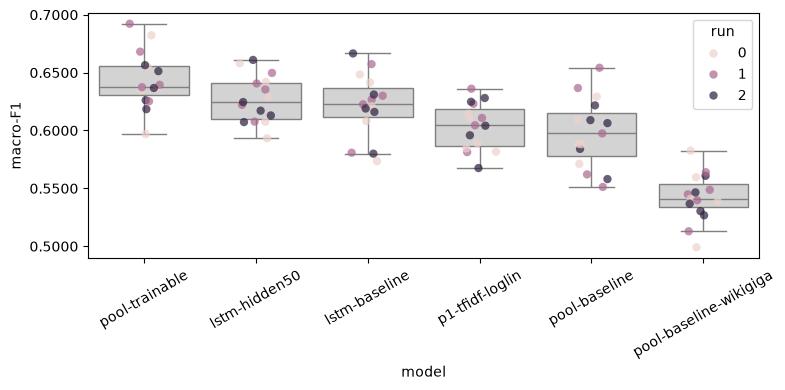

In [4]:
key_models = [
    'pool-trainable', 'lstm-hidden50', 'lstm-baseline',
    'p1-tfidf-loglin', 'pool-baseline', 'pool-baseline-wikigiga',
]
missing_models = set(key_models) - set(shared_scores['model'])
if missing_models:
    raise ValueError(f'Missing shared scores for: {sorted(missing_models)}')
key_scores = shared_scores[shared_scores['model'].isin(key_models)].copy()
key_scores['model'] = pd.Categorical(key_scores['model'], categories=key_models, ordered=True)
part1.analysis.plot_box_and_points(key_scores.sort_values('model'), metric='macro-F1')

### Answer to Question 5

- **Search:** The shared designs vary pooling, embedding source/trainability, preprocessing and optimisation; many comparisons change one factor around a baseline. The CSVs do not document the search order, completeness or all tested interactions.
- **Variance:** We pair the same 3 seeds ? 5 folds (15 macro-F1 values per design) and use a correlated Bayesian t-test with ROPE = 0.005.
- **Results:** `pool-trainable` scores **0.6438 ? 0.0246**, versus **0.5978 ? 0.0301** for frozen Twitter embeddings: ? = **+0.0460**, 15/15 folds favour trainable, and P(? > 0.005) = **0.998**. Twitter versus WikiGiga: ? = **+0.0557**, P = **0.999**; trainable pool versus Part 1: ? = **+0.0400**, P = **0.989**. The trainable model's seed means are **0.6411, 0.6525, 0.6378**.
- **Uncertain choice:** `lstm-hidden50` averages **0.6272** versus **0.6215** for `lstm-baseline`; ? = **+0.0057**, with 7/15 folds favouring hidden50 and P(? > 0.005) = **0.530**. This does not establish a meaningful improvement.
- **Limits:** Fold SD is descriptive: training folds overlap and seeds change both splits and initialisation. Multiple design selection can be optimistic; Part 1's folds lack prediction-based verification. Use devtest separately and reserve test for final evaluation.

## Question 6: Error Analysis

We compare 3,232 training tweets, paired by seed and fold across three seeds.
- **Pair:** frozen versus trainable Twitter pool embeddings; the BDA also includes an LSTM with different preprocessing.
- **Features:** token length, `!/?`, hashtags, mentions, heuristic negation and Twitter/WikiGiga OOV rates, using a common tokenizer.
- **Scope:** shared predictions do not cover WikiGiga, `pool-keep-punct-stop` or `lstm-hidden50`. This is not devtest.

In [5]:
SHARED_MODEL_A = 'pool-baseline-twitter'
SHARED_MODEL_B = 'pool-trainable'
shared_per_item = paired_oof_predictions(shared_predictions, SHARED_MODEL_A, SHARED_MODEL_B, SEEDS)

def make_shared_features(texts):
    twitter = load_embeddings('twitter')
    wikigiga = load_embeddings('wikigiga')
    tokenizer = create_tokenizer(twitter, lowercase=True, remove_punct=False, remove_stopwords=False)
    return extract_tweet_features(texts, tokenizer, twitter.vocab, wikigiga.vocab)

shared_features = make_shared_features(shared_per_item['text'].tolist())
shared_per_item = shared_per_item.merge(shared_features, on='text', validate='one_to_one')
shared_feature_groups, shared_feature_contrasts = summarize_oof_features(shared_per_item)
print(f'{len(shared_per_item)} distinct tweets, paired across {len(SEEDS)} seeds.')
display(shared_per_item[['correct_a', 'correct_b', 'difference']].mean().to_frame('mean'))
display(shared_feature_groups)
display(shared_feature_contrasts)

3232 distinct tweets, paired across 3 seeds.


,mean
correct_a,0.662851
correct_b,0.702455
difference,0.039604


,feature,group,tweets,mean_b_minus_a,lower_95,upper_95
0,length,above median,1549,0.036798,0.023666,0.049500
1,length,at/below median,1683,0.042187,0.030105,0.054466
2,punctuation,yes,720,0.038889,0.022222,0.055093
3,punctuation,no,2512,0.039809,0.029983,0.050027
4,hashtag,yes,1409,0.041401,0.027679,0.055122
5,hashtag,no,1823,0.038215,0.026513,0.049739
6,mention,yes,1447,0.040083,0.026952,0.052753
7,mention,no,1785,0.039216,0.027638,0.051167
8,negation,yes,833,0.043617,0.027201,0.060424
9,negation,no,2399,0.038210,0.027928,0.048215


,feature,contrast,difference_in_gains,lower_95,upper_95
0,length,above median minus at/below median,-0.005389,-0.023194,0.012566
1,punctuation,yes minus no,-0.000920,-0.020244,0.017623
2,hashtag,yes minus no,0.003185,-0.014279,0.021007
3,mention,yes minus no,0.000867,-0.016360,0.018115
4,negation,yes minus no,0.005407,-0.013724,0.025544
5,oov_rate,has OOV minus no OOV,0.009264,-0.008846,0.026382
6,oov_wikigiga,has OOV minus no OOV,0.011103,-0.006533,0.028798


*Note:* These are paired **accuracy** differences, not macro-F1. Intervals bootstrap tweets after averaging seeds; they omit training uncertainty and multiple-comparison adjustment and do not imply causality.

In [6]:
class_results = shared_per_item.groupby('gold').agg(
    tweets=('difference', 'size'), correctness_a=('correct_a', 'mean'),
    correctness_b=('correct_b', 'mean'), difference=('difference', 'mean'))
class_results.index = [shared_label_names[int(i)] for i in class_results.index]
display(class_results)
# Inspect examples locally; tweets are not sent to an external service.
shared_examples = shared_per_item[shared_per_item['difference'] != 0].copy()
shared_examples['absolute_difference'] = shared_examples['difference'].abs()
display(shared_examples.sort_values('absolute_difference', ascending=False)
        [['text', 'gold', 'length', 'oov_rate', 'oov_wikigiga', 'correct_a', 'correct_b', 'difference']].head(20))

,tweets,correctness_a,correctness_b,difference
anger,1400,0.829524,0.827381,-0.002143
joy,683,0.578331,0.675451,0.097121
optimism,294,0.337868,0.379819,0.041950
sadness,855,0.569201,0.630409,0.061209


### Bayesian Data Analysis (BDA) on shared predictions

We fit the tutorial's Bayesian correctness model on **seed 0** for all three models, with Laplace priors on system shifts and feature weights. Using one seed avoids treating repeated predictions as independent; predictions from different systems on the same tweet are still treated as independent, potentially making intervals too narrow. The averaged model-based accuracy is not necessarily observed accuracy.

In [6]:
import arviz as az
import jax
import part2.analysis
from itertools import combinations

SHARED_BDA_SEED = 0
SHARED_BDA_MODELS = ['pool-baseline-twitter', 'pool-trainable', 'lstm-baseline']
SHARED_BDA_WARMUP, SHARED_BDA_SAMPLES, SHARED_BDA_CHAINS = 500, 500, 2
from part2.error_analysis import prepare_shared_bda

if SHARED_BDA_SEED not in SEEDS:
    raise ValueError('Select a seed available in the shared predictions.')
shared_bda, shared_systems, shared_x, shared_feature_names = prepare_shared_bda(
    shared_predictions, shared_features, SHARED_BDA_MODELS, SHARED_BDA_SEED, shared_label_names)
print(f'JAX devices: {jax.devices()}; seed {SHARED_BDA_SEED}; {len(shared_bda)} model/tweet rows.')
shared_mcmc = part2.analysis.fit_bda_model(
    num_systems=len(shared_systems), sys_id=shared_bda['system_id'].to_numpy(dtype=int),
    features=shared_x, correctness=shared_bda['correct'].to_numpy(dtype=int),
    num_warmup=SHARED_BDA_WARMUP, num_samples=SHARED_BDA_SAMPLES,
    num_chains=SHARED_BDA_CHAINS, seed=0)
shared_posterior_data = part2.analysis.posterior_to_arviz(
    shared_mcmc, system_names=SHARED_BDA_MODELS, feature_names=shared_feature_names)
shared_diagnostics = az.summary(shared_posterior_data, var_names=['global_mean', 'sys_shift', 'w'], kind='diagnostics', round_to='none')
shared_divergences = int(shared_mcmc.get_extra_fields()['diverging'].sum())
print('Divergences:', shared_divergences)
display(shared_diagnostics)
if shared_divergences or shared_diagnostics['r_hat'].isna().any() or (shared_diagnostics['r_hat'] > 1.01).any():
    print('WARNING: unreliable or unavailable MCMC diagnostics; do not interpret these posteriors yet.')
if shared_diagnostics[['ess_bulk', 'ess_tail']].isna().any().any() or (shared_diagnostics[['ess_bulk', 'ess_tail']] < 100).any().any():
    print('WARNING: low or unavailable effective sample size for at least one parameter.')

JAX devices: [CpuDevice(id=0)]; seed 0; 9696 model/tweet rows.


  0%|          | 0/1000 [00:00<?, ?it/s]

warmup:   5%|▌         | 50/1000 [00:00<00:14, 64.20it/s, 15 steps of size 2.03e-02. acc. prob=0.85]

warmup:  10%|█         | 100/1000 [00:01<00:08, 109.37it/s, 119 steps of size 1.69e-02. acc. prob=0.86]

warmup:  15%|█▌        | 150/1000 [00:01<00:08, 96.38it/s, 63 steps of size 1.19e-01. acc. prob=0.88]  

warmup:  20%|██        | 200/1000 [00:02<00:11, 68.96it/s, 31 steps of size 1.13e-01. acc. prob=0.88]

... (37 outputs left out)

sample: 100%|██████████| 1000/1000 [00:23<00:00, 36.29it/s, 255 steps of size 3.17e-02. acc. prob=0.95]

sample: 100%|██████████| 1000/1000 [00:23<00:00, 41.73it/s, 255 steps of size 3.17e-02. acc. prob=0.95]

Divergences: 0


,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
global_mean,381.735084,236.849670,1.007195,0.029907,0.036231
sys_shift[pool-baseline-twitter],379.224527,210.664108,1.007059,0.029598,0.035865
sys_shift[pool-trainable],385.881824,253.491634,1.007884,0.029307,0.035911
sys_shift[lstm-baseline],379.001646,201.019152,1.006961,0.030479,0.036419
"w[pool-baseline-twitter, pred:anger]",1476.505192,995.622648,0.999748,0.001221,0.001427
"w[pool-baseline-twitter, pred:joy]",1252.047616,776.580464,0.999464,0.001283,0.001364
"w[pool-baseline-twitter, pred:optimism]",2234.475245,831.634023,1.005526,0.000917,0.001612
"w[pool-baseline-twitter, length]",1983.029481,896.491131,1.000057,0.000876,0.001207
"w[pool-baseline-twitter, punctuation]",2516.470010,786.762266,1.004792,0.000724,0.001147
"w[pool-baseline-twitter, hashtag]",2133.090599,870.733125,1.006186,0.000818,0.001179


In [7]:
shared_posterior = shared_mcmc.get_samples()
shared_bda_pairs, shared_bda_features = [], []
for a, b in combinations(SHARED_BDA_MODELS, 2):
    ia, ib = shared_systems[a], shared_systems[b]
    delta = shared_posterior['accuracy'][:, ib] - shared_posterior['accuracy'][:, ia]
    shared_bda_pairs.append({'model_a': a, 'model_b': b, 'mean_b_minus_a': float(np.mean(delta)),
                             'lower_95': float(np.quantile(delta, 0.025)),
                             'upper_95': float(np.quantile(delta, 0.975)),
                             'prob_b_greater_a': float(np.mean(delta > 0))})
    for j, feature in enumerate(shared_feature_names):
        delta_w = shared_posterior['w'][:, ib, j] - shared_posterior['w'][:, ia, j]
        shared_bda_features.append({'model_a': a, 'model_b': b, 'feature': feature,
                                    'mean_slope_difference': float(np.mean(delta_w)),
                                    'lower_95': float(np.quantile(delta_w, 0.025)),
                                    'upper_95': float(np.quantile(delta_w, 0.975))})
display(pd.DataFrame(shared_bda_pairs))
display(pd.DataFrame(shared_bda_features))
print('BDA comparisons are model-based average correctness, not macro-F1; check diagnostics and dependence caveats.')

,model_a,model_b,mean_b_minus_a,lower_95,upper_95,prob_b_greater_a
0,pool-baseline-twitter,pool-trainable,0.039856,0.016743,0.061858,1.000
1,pool-baseline-twitter,lstm-baseline,0.017430,-0.005591,0.040390,0.912
2,pool-trainable,lstm-baseline,-0.022426,-0.046390,0.000720,0.032


,model_a,model_b,feature,mean_slope_difference,lower_95,upper_95
0,pool-baseline-twitter,pool-trainable,pred:anger,0.011250,-0.113104,0.144281
1,pool-baseline-twitter,pool-trainable,pred:joy,-0.044707,-0.177036,0.075376
2,pool-baseline-twitter,pool-trainable,pred:optimism,-0.018101,-0.134926,0.101576
3,pool-baseline-twitter,pool-trainable,length,-0.071529,-0.184185,0.041832
4,pool-baseline-twitter,pool-trainable,punctuation,0.046564,-0.059189,0.161138
5,pool-baseline-twitter,pool-trainable,hashtag,0.040949,-0.064953,0.144607
6,pool-baseline-twitter,pool-trainable,mention,-0.003120,-0.114510,0.110389
7,pool-baseline-twitter,pool-trainable,negation,0.024413,-0.088391,0.131750
8,pool-baseline-twitter,pool-trainable,oov_rate,0.022278,-0.141846,0.188385
9,pool-baseline-twitter,pool-trainable,oov_wikigiga,-0.004647,-0.172868,0.166389


BDA comparisons are model-based average correctness, not macro-F1; check diagnostics and dependence caveats.


### Posterior plots

Posterior medians and 50% / 95% HDIs for shifts, model-based accuracy and standardised feature weights. Weights are on the log-odds scale; associations are exploratory and conditional on other features, including predicted class.

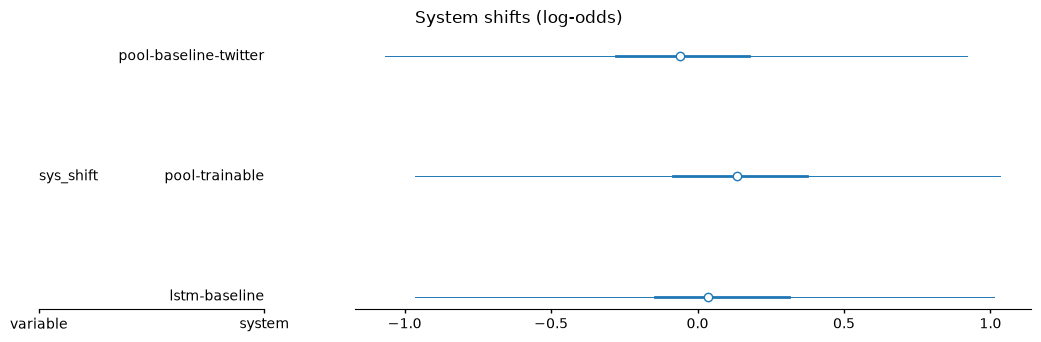

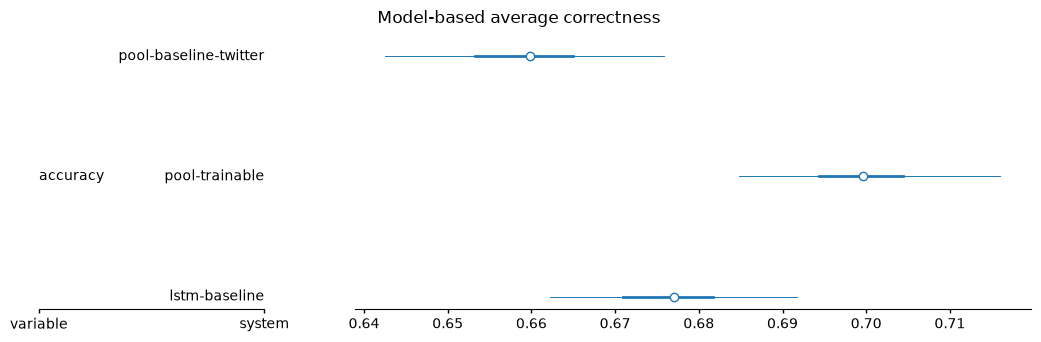

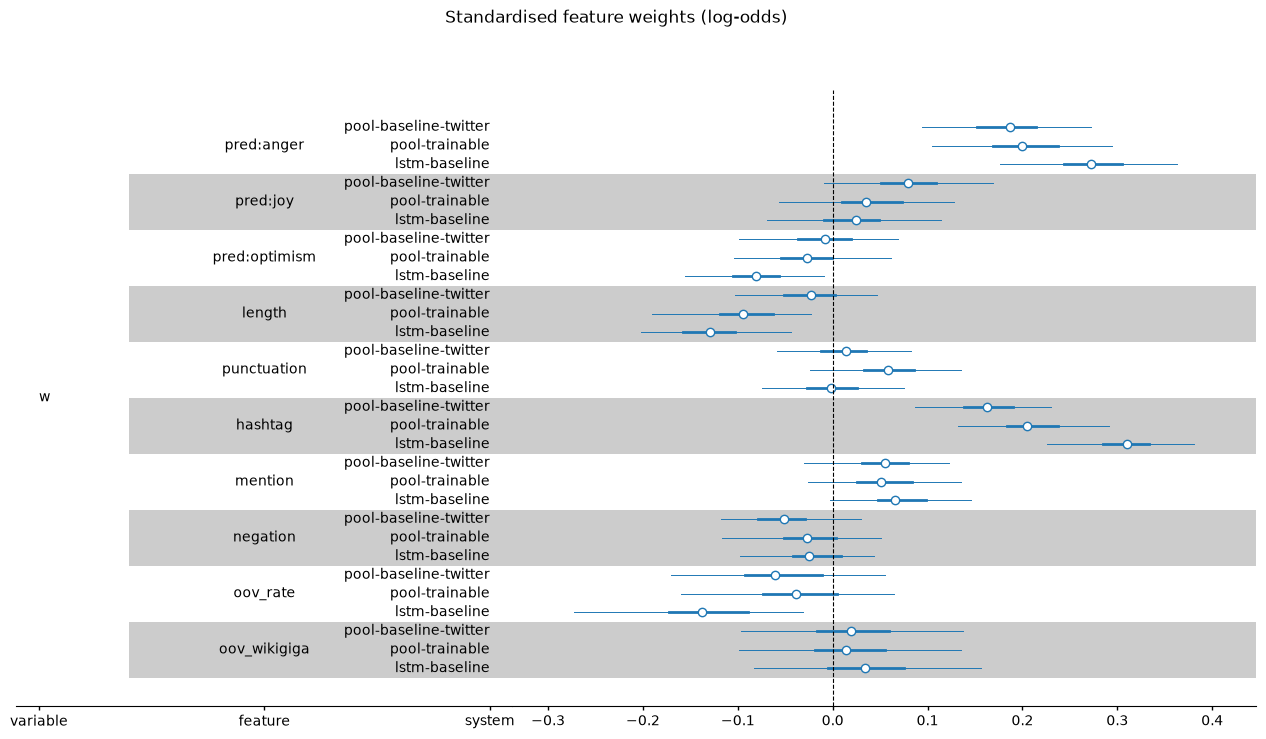

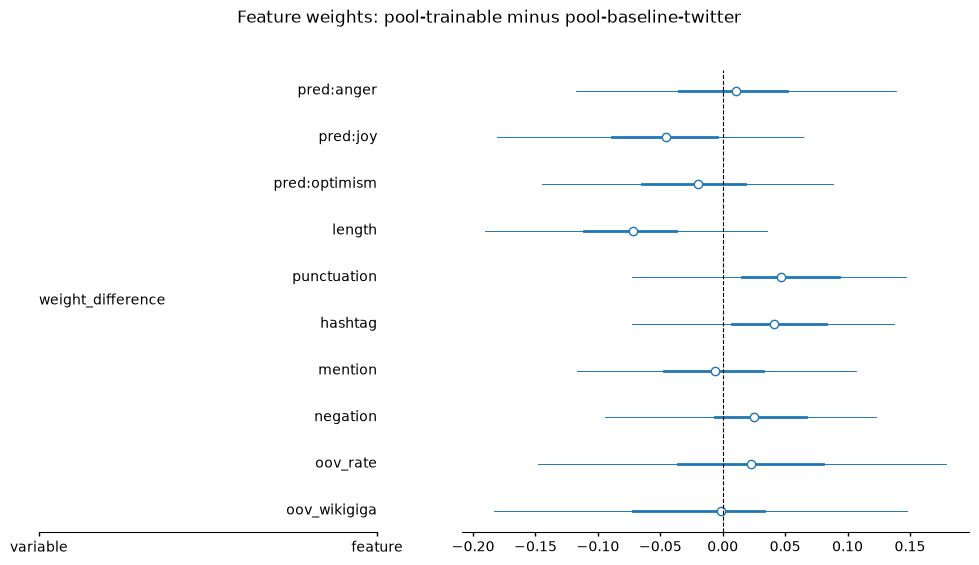

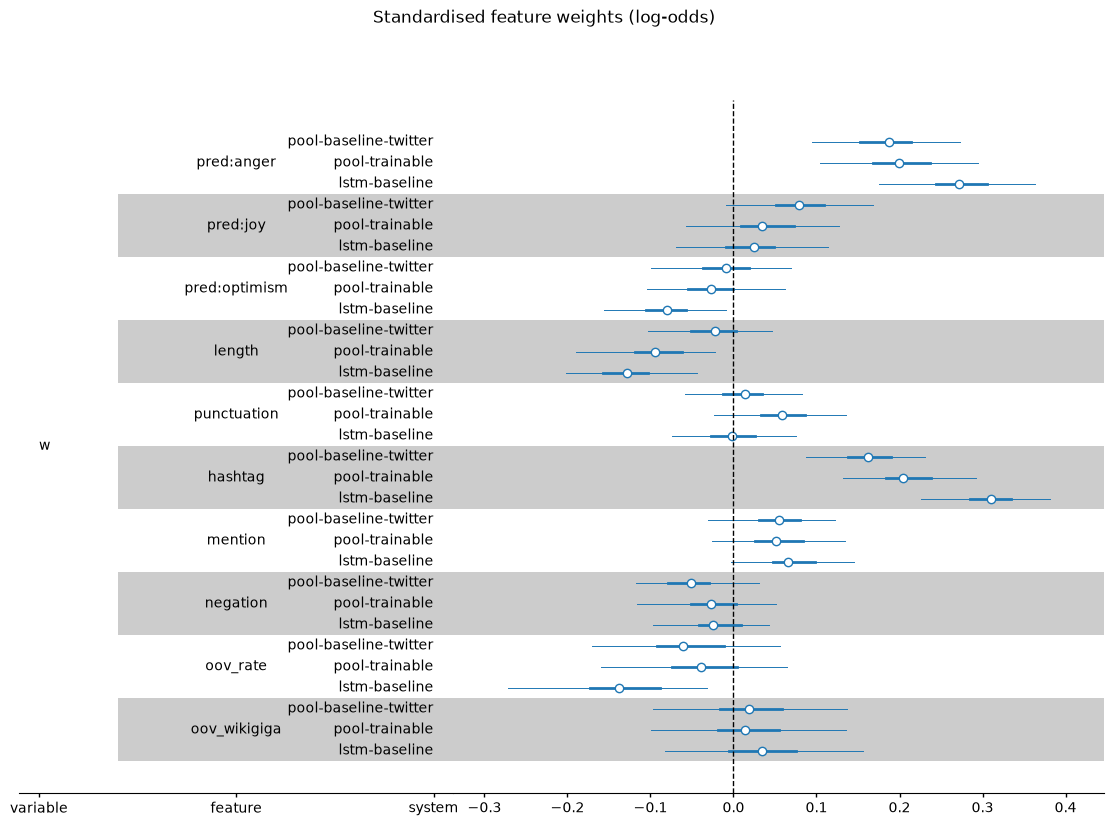

In [8]:
from part2.error_analysis import plot_bda_forests
plot_bda_forests(shared_posterior_data, SHARED_MODEL_A, SHARED_MODEL_B)

import matplotlib.pyplot as plt

plot_data = shared_posterior_data.copy()
plot_data['posterior'] = (
    shared_posterior_data.posterior['w']
    .transpose('chain', 'draw', 'feature', 'system')
    .to_dataset()
)
az.plot_forest(
    plot_data, var_names=['w'], combined=True, shade_label='feature',
    point_estimate='median', ci_kind='hdi', ci_probs=(0.5, 0.95),
    figure_kwargs={'figsize': (14, 9), 'width_ratios': [2, 3], 'layout': 'none'},
)
plt.gcf().axes[-1].axvline(0, color='black', linestyle='--', linewidth=1)
plt.gcf().suptitle('Standardised feature weights (log-odds)')
plt.show()

### Answer to Question 6

- **Features tested:** length, punctuation, hashtags, mentions, negation and two OOV rates; BDA also includes predicted-class indicators. Sarcasm and syntax were not tested.
- **Frozen versus trainable pool:** mean paired correctness improves by **3.96 percentage points** over three seeds. Every tested bootstrap feature-group contrast and every seed-0 BDA slope-difference interval includes zero; this does not prove that the features have no effect. For Twitter OOV, the group contrast is **+0.93 pp** (95% item-bootstrap interval **?0.88 to 2.64 pp**). Seed-0 BDA estimates P(model-based gain > 0) as **1.000** from the posterior samples, not as a guarantee.
- **Classes:** exploratory correctness gains are **+9.71 pp for joy**, **+6.12 pp for sadness**, **+4.20 pp for optimism**, and **?0.21 pp for anger**. Trainable-pool correctness for gold `optimism` is **38.0%** (294 tweets), versus **82.7%** for `anger` (1,400 tweets). Predicted-class BDA weights are not gold-class recall.
- **Pool versus LSTM:** in seed 0, the LSTM-minus-frozen-pool hashtag slope is **+0.149** (95% equal-tailed posterior interval **0.050 to 0.258**). The LSTM's length and Twitter OOV weights are negative, but their between-model slope intervals include zero. These associations are exploratory: preprocessing also differs, the same tweets occur across systems, and many features were inspected. The run had **0 divergences** and all R-hat values below **1.01**.
- **Priorities:** inspect optimism confusions first; test class weighting or oversampling only on training folds and monitor all classes. Consider subword/contextual encoders as hypotheses, not proven OOV or length fixes. Compare models, including WikiGiga and `pool-keep-punct-stop`, on devtest without repeated tuning; reserve test for final evaluation.